# Whole-cell structure analysis: all folds

The original GT, MPNN, and mean + ResNet checkpoints are evaluated on their corresponding held-out 10-node windows, without retraining the ablations. Primary metrics exclude cells without known nucleus coordinates; other cells use the original 5 µm Euclidean nucleus exclusion. These are the earlier eight-class models, with unsupported classes excluded from macro metrics by the original metric definition.

Every plot shows equal-weight fold means with pointwise 95% Student-t intervals across the five folds. For randomized interventions, average the three seeds **within each fold first**; the seeds are not additional folds. Fold training sets overlap, so the intervals describe fold variability. No five-fold figure is drawn until all five fold caches are present.

Q/K/V projections mix dimensions within nodes; attention mixes node value vectors. `uniform_attention` retains mixing with equal weights. `nodewise_mean_readout` disables attention updates to ordinary nodes while retaining uniform CLS pooling. `no_attention_update` also blocks CLS readout and is a degenerate diagnostic. Inference ablations measure reliance, not the performance of retrained ablated architectures. Attention/gamma and message-branch norms are descriptive, not fractions of causal prediction importance.

Activation statistics use class-stratified samples (up to 20,000 windows per supported class per fold). Their means describe those samples, not the distribution weighted by all test windows.

In [1]:
%matplotlib inline
from pathlib import Path
import json,sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/train_gnn.py').exists())
sys.path.insert(0,str(root/'analysis/report_folds_20261012'))
from all_folds import mean_ci
base=root/'analysis/all_windows/structure_ablation'
folders=[base]+[base/f'fold{f}' for f in range(1,5)]
ready=all((p/'cache'/f'ablations_seed{s}.json').exists() for p in folders for s in range(3))
weights_ready=all((p/'cache/weight_analysis.json').exists() for p in folders)
display(pd.DataFrame([{'fold':f,'metrics_ready':all((p/'cache'/f'ablations_seed{s}.json').exists() for s in range(3)),
                      'weights_ready':(p/'cache/weight_analysis.json').exists()} for f,p in enumerate(folders)]))
rows=[]
if ready:
    for fold,folder in enumerate(folders):
        for seed in range(3):
            for row in json.loads((folder/'cache'/f'ablations_seed{seed}.json').read_text())['rows']:
                for unit in ['window','cell']:
                    rows.append({'fold':fold,'seed':seed,'model':row['model'],'condition':row['condition'],'unit':unit,
                                 **{k:v for k,v in row['strict_soma'][unit].items() if isinstance(v,(float,int))}})
    df=pd.DataFrame(rows).groupby(['fold','model','condition','unit'],as_index=False).mean(numeric_only=True)
if weights_ready:
    weights=[json.loads((p/'cache/weight_analysis.json').read_text()) for p in folders]
    stats=[w['activation_statistics'] for w in weights]
    def series(model,key):return np.array([s[model][key]['mean'] for s in stats])


,fold,metrics_ready,weights_ready
0,0,True,True
1,1,True,True
2,2,True,True
3,3,True,True
4,4,True,True


## Held-out inference interventions

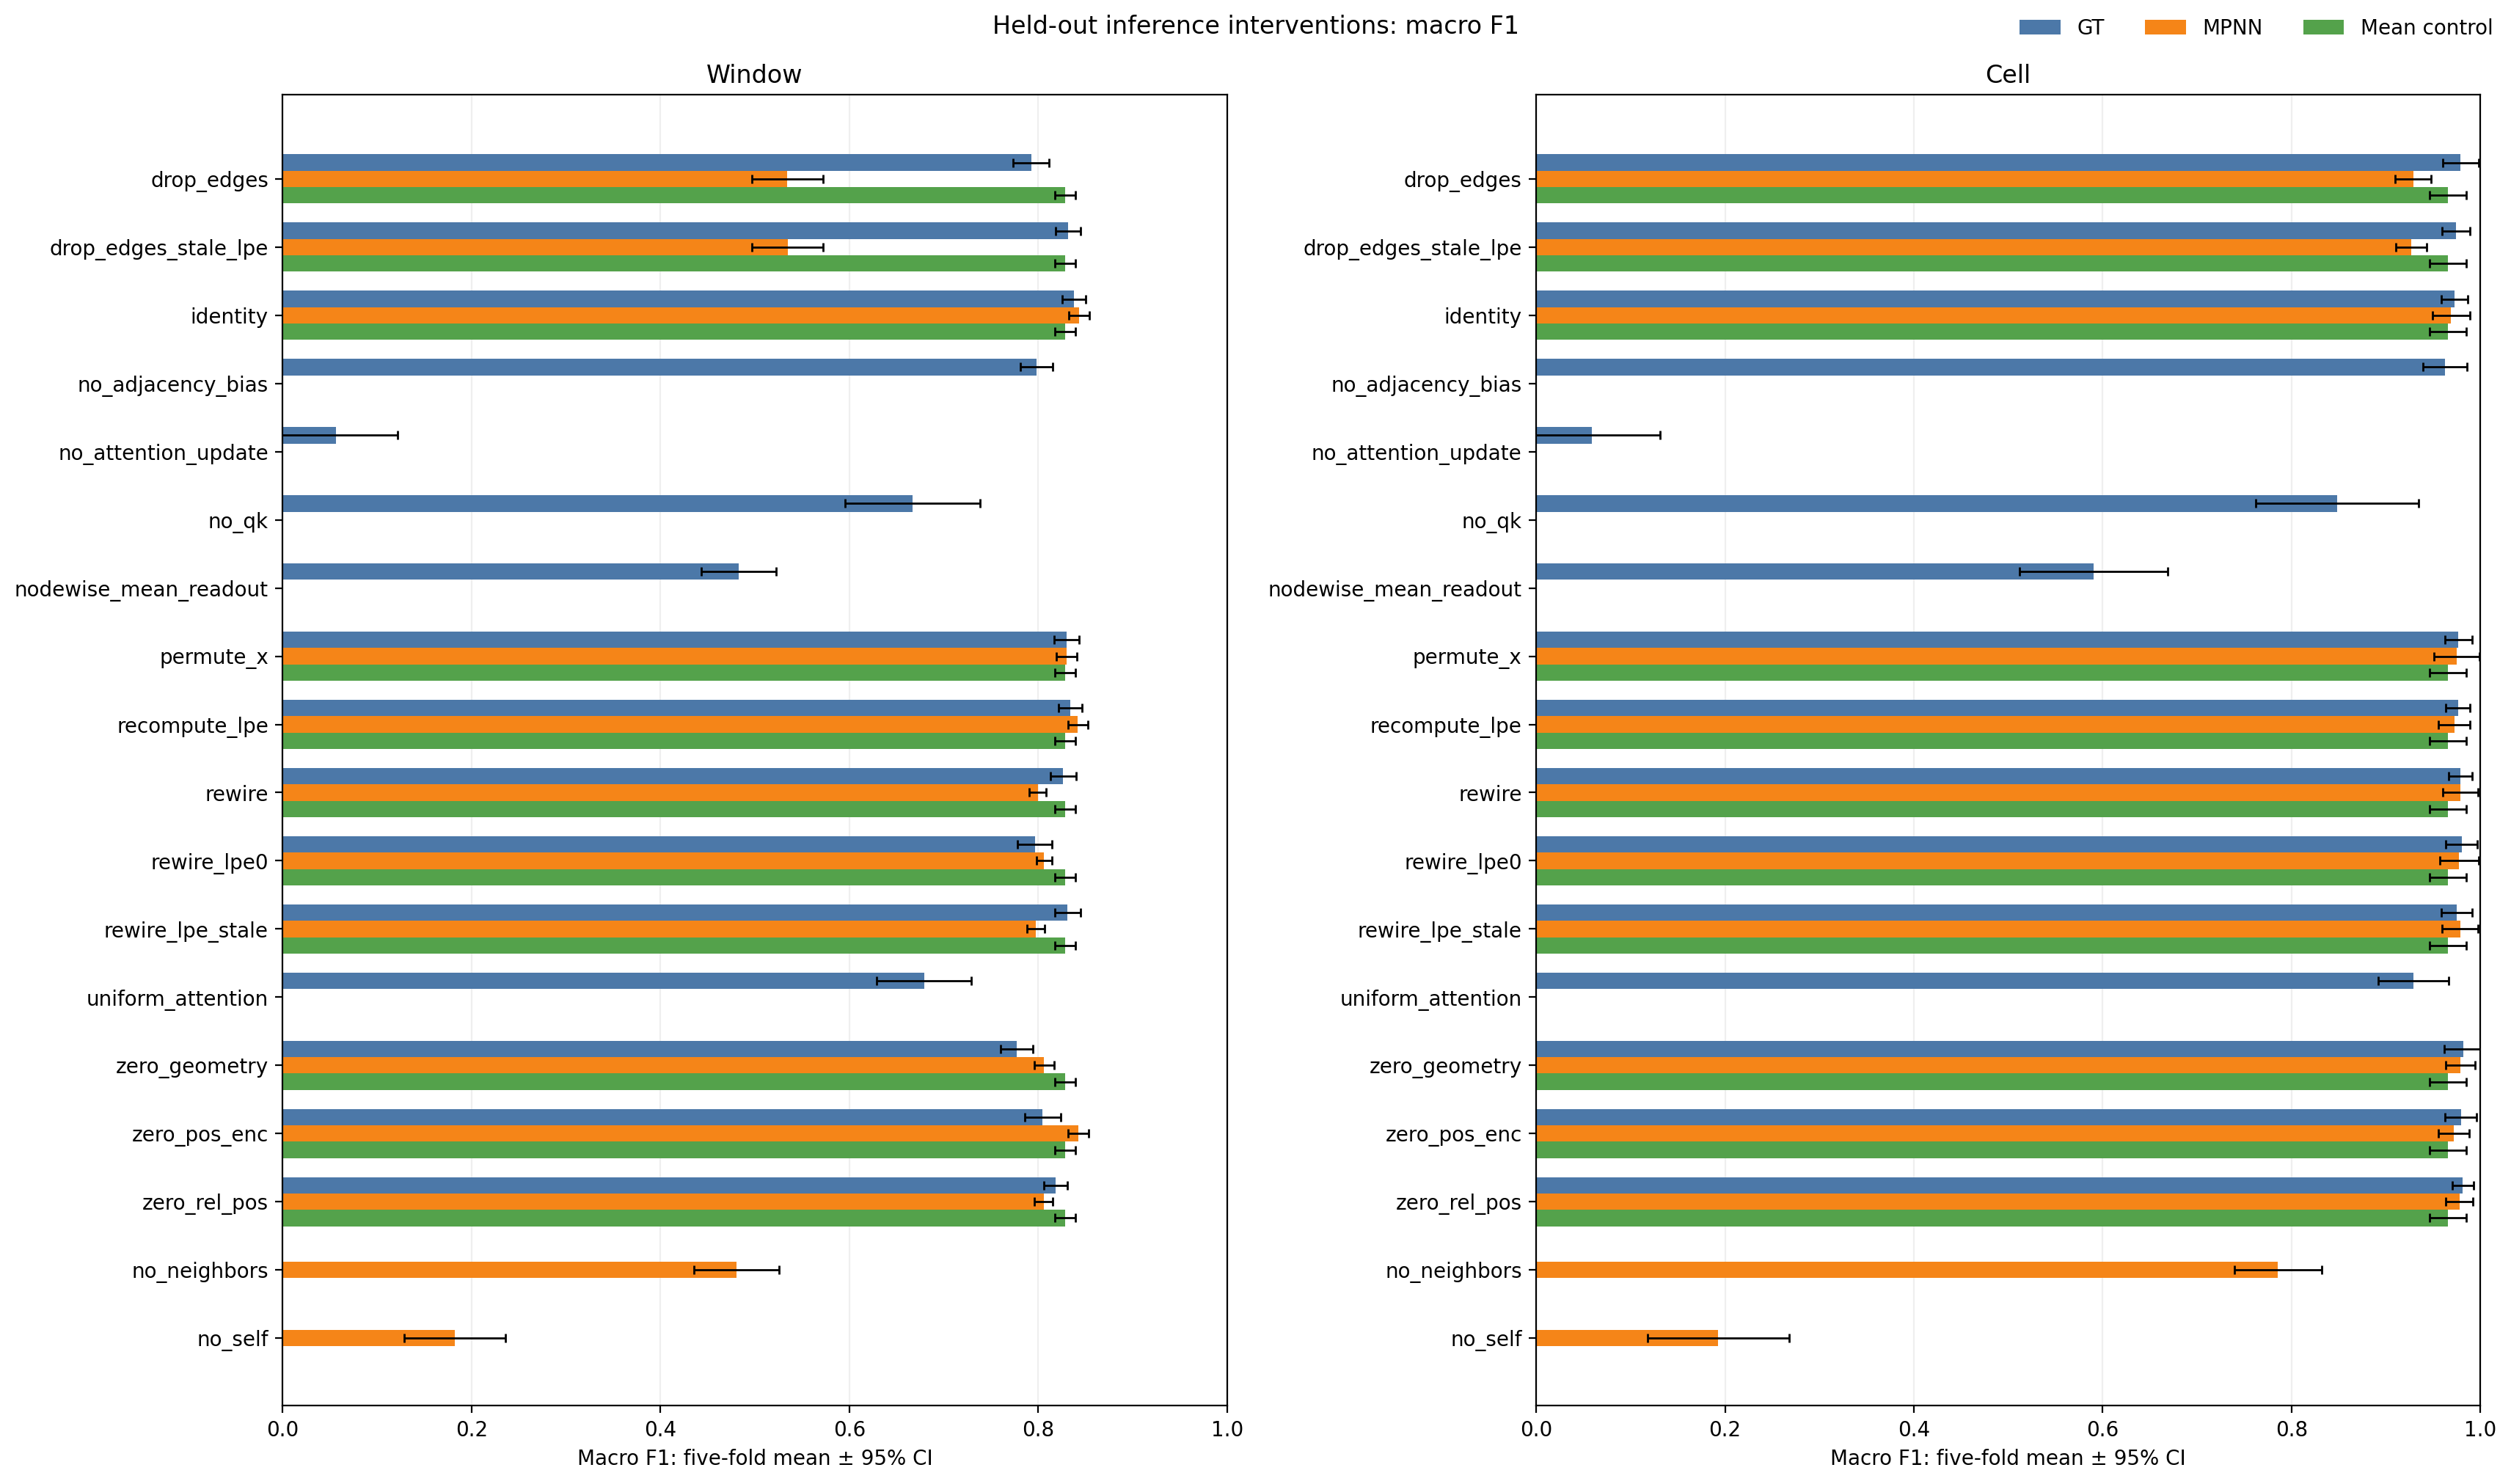

                                           macro_f1          
                                               mean       std
model        condition             unit                      
GT           drop_edges            cell    0.978985  0.015305
                                   window  0.792489  0.015481
             drop_edges_stale_lpe  cell    0.974328  0.011881
                                   window  0.831925  0.010590
             identity              cell    0.972740  0.011429
                                   window  0.837613  0.009984
             no_adjacency_bias     cell    0.962442  0.018554
                                   window  0.798446  0.013794
             no_attention_update   cell    0.059129  0.057968
                                   window  0.056391  0.052828
             no_qk                 cell    0.848060  0.069569
                                   window  0.667049  0.057642
             nodewise_mean_readout cell    0.590196  0.063237
        

In [ ]:
from matplotlib.patches import Patch

if ready:
    model_colors = {'GT': '#4C78A8', 'MPNN': '#F58518', 'Mean control': '#54A24B'}
    fig, axes = plt.subplots(1, 2, figsize=(17, 10), sharex=True,
                             layout='constrained')
    order = list(dict.fromkeys(df.condition))
    height = 0.24
    for ax, unit in zip(axes, ['window', 'cell']):
        for (model, color), offset in zip(model_colors.items(), [-height, 0, height]):
            points = df[(df.model == model) & (df.unit == unit)]
            for condition, values in points.groupby('condition'):
                mean, low, high = mean_ci(values.sort_values('fold').macro_f1)
                ax.barh(order.index(condition) + offset, mean, height=height,
                        color=color, xerr=[[mean - low], [high - mean]],
                        capsize=2, error_kw={'elinewidth': 1})
        ax.set(yticks=range(len(order)), yticklabels=order, xlim=(0, 1),
               xlabel='Macro F1: five-fold mean ± 95% CI', title=unit.capitalize())
        ax.invert_yaxis()
        ax.set_axisbelow(True)
        ax.grid(axis='x', alpha=0.2)
    fig.legend(handles=[Patch(facecolor=color, label=model)
                        for model, color in model_colors.items()],
               loc='outside upper right', ncol=3, frameon=False)
    fig.suptitle('Held-out inference interventions: macro F1')
    output_dir = root / 'analysis/all_windows/figures'
    output_dir.mkdir(parents=True, exist_ok=True)
    output_stem = output_dir / 'structure_ablation_all_folds_macro_f1_bars'
    fig.savefig(output_stem.with_suffix('.png'), dpi=200, bbox_inches='tight')
    fig.savefig(output_stem.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()
    display(df.groupby(['model', 'condition', 'unit'])[['macro_f1']].agg(['mean', 'std']))
else:
    print('Waiting for all five folds; no partial five-fold means displayed.')


## Attention allocation across ordinary-node queries

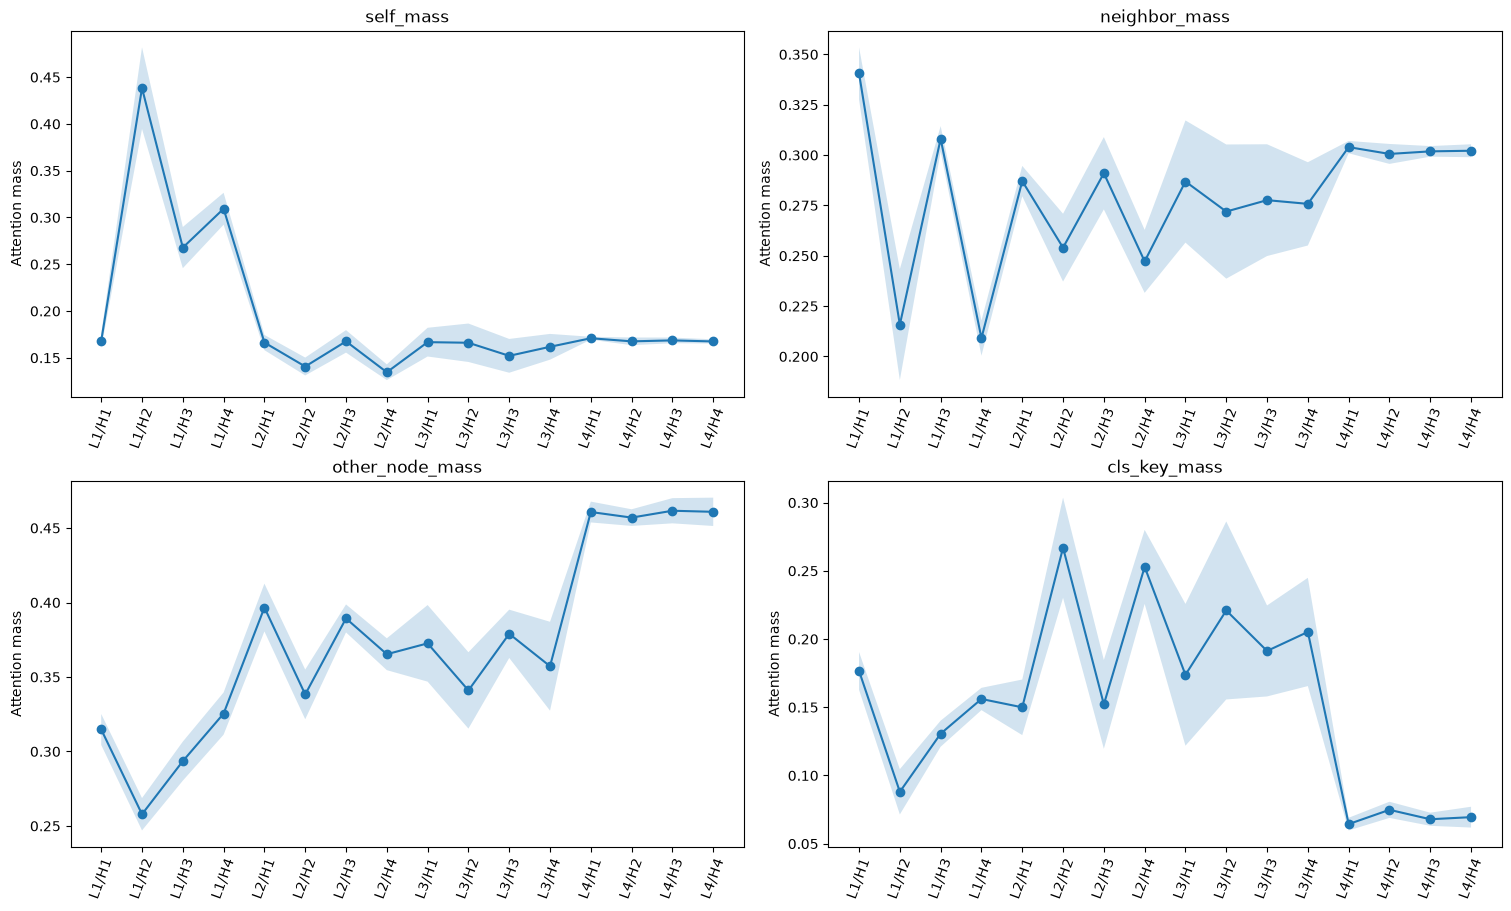

In [3]:
if weights_ready:
    labels=[f'L{l+1}/H{h+1}' for l in range(4) for h in range(4)]
    fig,axes=plt.subplots(2,2,figsize=(15,9),layout='constrained')
    for ax,term in zip(axes.flat,['self_mass','neighbor_mass','other_node_mass','cls_key_mass']):
        values=np.stack([series('GT',f'GT/layer{l}/head{h}/node/{term}') for l in range(4) for h in range(4)],axis=1)
        mean,low,high=mean_ci(values);x=np.arange(16)
        ax.plot(x,mean,'o-');ax.fill_between(x,low,high,alpha=.2)
        ax.set(xticks=x,xticklabels=labels,ylabel='Attention mass',title=term);ax.tick_params(axis='x',rotation=70)
    plt.show()


## QK versus adjacency logit contributions

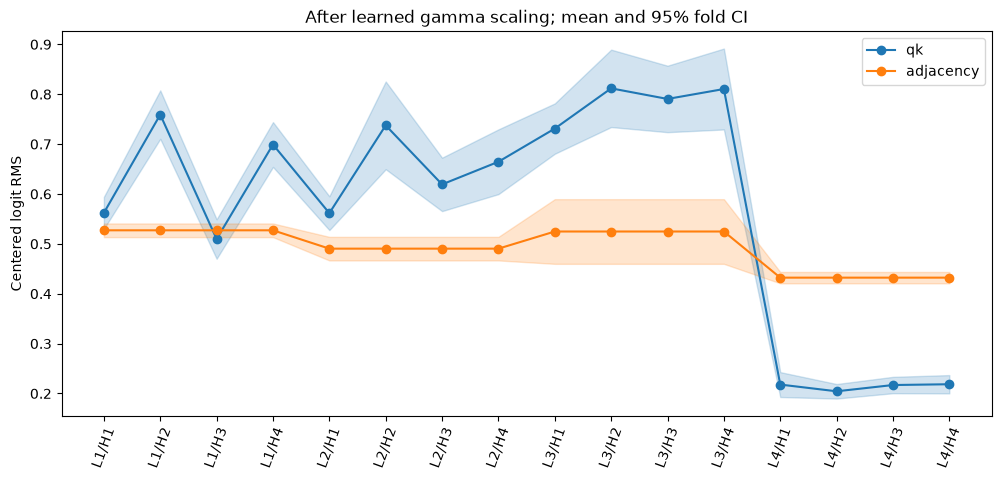

In [4]:
if weights_ready:
    fig,ax=plt.subplots(figsize=(12,5))
    for term in ['qk','adjacency']:
        values=np.stack([series('GT',f'GT/layer{l}/head{h}/node/{term}_centered_logit_rms') for l in range(4) for h in range(4)],axis=1)
        mean,low,high=mean_ci(values);line,=ax.plot(range(16),mean,'o-',label=term);ax.fill_between(range(16),low,high,color=line.get_color(),alpha=.2)
    ax.set(xticks=range(16),xticklabels=labels,ylabel='Centered logit RMS',title='After learned gamma scaling; mean and 95% fold CI');ax.tick_params(axis='x',rotation=70);ax.legend();plt.show()


## CLS readout by radial rank

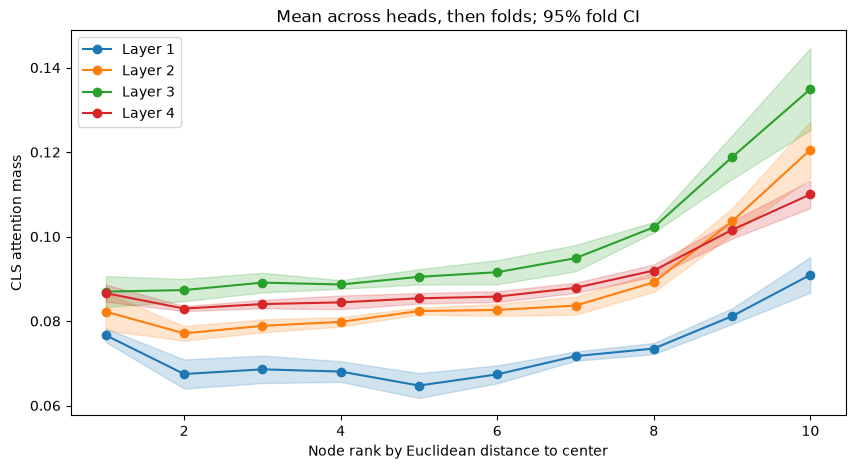

In [5]:
if weights_ready:
    fig,ax=plt.subplots(figsize=(10,5))
    for l in range(4):
        values=np.stack([np.mean([series('GT',f'GT/layer{l}/head{h}/cls/radial_rank{rank}_mass') for h in range(4)],axis=0) for rank in range(10)],axis=1)
        mean,low,high=mean_ci(values);x=np.arange(1,11);line,=ax.plot(x,mean,'o-',label=f'Layer {l+1}');ax.fill_between(x,low,high,color=line.get_color(),alpha=.2)
    ax.set(xlabel='Node rank by Euclidean distance to center',ylabel='CLS attention mass',title='Mean across heads, then folds; 95% fold CI');ax.legend();plt.show()


## MPNN neighbor/self contribution distribution

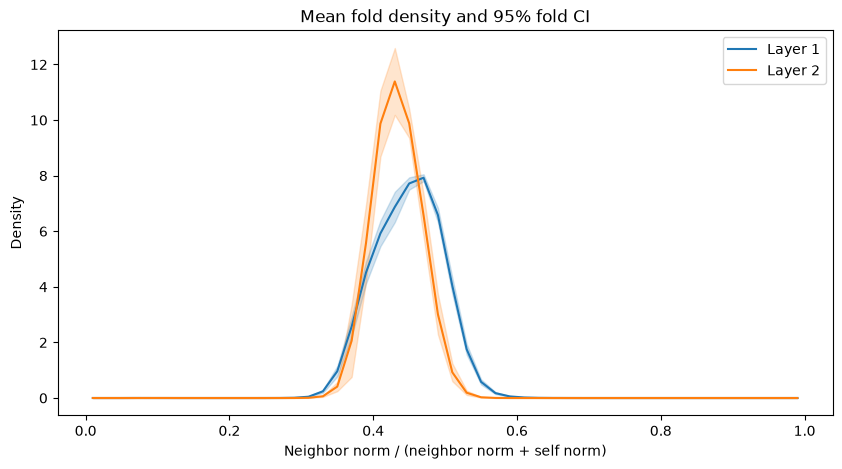

In [6]:
if weights_ready:
    fig,ax=plt.subplots(figsize=(10,5))
    for l in range(2):
        hist=[s['MPNN'][f'MPNN/layer{l}/neighbor_norm_fraction']['histogram'] for s in stats]
        edges=np.array(hist[0]['edges']);width=np.diff(edges)
        values=np.array([np.array(h['counts'])/sum(h['counts'])/width for h in hist])
        mean,low,high=mean_ci(values);x=(edges[:-1]+edges[1:])/2
        line,=ax.plot(x,mean,label=f'Layer {l+1}');ax.fill_between(x,low,high,color=line.get_color(),alpha=.2)
    ax.set(xlabel='Neighbor norm / (neighbor norm + self norm)',ylabel='Density',title='Mean fold density and 95% fold CI');ax.legend();plt.show()


## Parameter magnitudes
Descriptive norms are not a ranking of aggregator versus decoder importance.

In [7]:
if weights_ready:
    rows=[]
    for model,parameters in weights[0]['parameter_statistics'].items():
        for name in parameters:
            values=[w['parameter_statistics'][model][name]['rms'] for w in weights]
            mean,low,high=mean_ci(values)
            rows.append({'model':model,'parameter':name,'RMS_mean':mean,'CI_low':low,'CI_high':high})
    display(pd.DataFrame(rows))


,model,parameter,RMS_mean,CI_low,CI_high
0,GT,graph_transformer.cls_token,1.020837,1.017465,1.024210
1,GT,graph_transformer.cls_pos_embedding,0.810524,0.807774,0.813274
2,GT,graph_transformer.to_node_embedding.0.weight,0.071162,0.070905,0.071418
3,GT,graph_transformer.to_node_embedding.0.bias,0.069393,0.069160,0.069627
4,GT,graph_transformer.to_node_embedding.2.weight,0.038236,0.037863,0.038608
...,...,...,...,...,...
153,Mean control,cls_head.heads.2.bias,0.051044,0.050511,0.051577
154,Mean control,cls_head.heads.3.weight,0.094669,0.088676,0.100662
155,Mean control,cls_head.heads.3.bias,0.034052,0.032916,0.035188
156,Mean control,cls_head.heads.4.weight,0.104460,0.091228,0.117693
